# 08 · Measuring the brain
**Kuizi brain walkthrough, notebook 8 of 10**

A model is only as good as the way we test it. Three ideas:

1. **Test on new students.** Split by student, never by answer. Otherwise the model has already
   seen the same student and looks better than it will be in real life (**data leakage**).
2. **AUC** (area under the ROC curve): pick one right answer and one wrong answer at random; AUC is
   the chance that the model gave the right answer a higher probability. 0.5 = coin toss, 1 = perfect.
3. **Calibration**: when the model says 70 %, students should be right about 70 % of the time.
   Kuizi shows mastery percentages and a Bac grade estimate, so a well-ranked but badly calibrated
   model would mislead students. **ECE** (expected calibration error) is the average gap.

Then a rule decides when a new model may replace the current one: the **champion / challenger gate**.

| In this notebook | Production ticket |
| --- | --- |
| Benchmark metrics and protocol | T040 |
| Champion / challenger gate with automatic rollback | T047 |
| Model monitoring (drift, leakage tests) | T050 |

<div dir="rtl" lang="ar">

## ٠٨ · كيف نقيس جودة الدماغ

النموذج جيّد بقدر جودة طريقة اختباره. ثلاث أفكار:
١. <b>نختبر على تلاميذ جدد</b>: نقسم حسب التلميذ لا حسب الإجابة، وإلا يكون النموذج قد رأى نفس التلميذ فيبدو أفضل ممّا هو (<b>تسرّب البيانات</b>).
٢. <b>AUC</b>: نختار إجابة صحيحة وإجابة خاطئة عشوائيًا؛ AUC هو احتمال أن يعطي النموذج الصحيحة احتمالًا أعلى. 0.5 = رمي قطعة نقود، 1 = كمال.
٣. <b>المعايرة</b>: عندما يقول النموذج 70%، يجب أن يصيب التلاميذ نحو 70% من المرّات. كويزي يعرض نسب تمكّن وتقديرًا لمعدّل الباكالوريا،
فالنموذج سيّئ المعايرة يضلّل التلاميذ. <b>ECE</b> هو متوسّط الفرق.

ثم قاعدة تقرّر متى يحقّ لنموذج جديد أن يحلّ محلّ الحالي: <b>بوّابة البطل / المنافس</b>.

</div>

In [1]:
# Concept: model settings · Production: T040
EPOCHS, BATCH, LR = 6, 16, 1e-3   # SAINT+ training settings (see notebook 7)

In [2]:
# Concept: data leakage: splitting by answer instead of by student · Production: T040, T050
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from kuizi_brain import data as D, models as M, metrics as X
real = D.load_assist2009()
rng = np.random.default_rng(0)
by_row = rng.random(len(real)) < 0.2
irt = M.IRT(real.student.max() + 1, real.item.max() + 1)
irt.fit(real.student[~by_row].values, real.item[~by_row].values, real.correct[~by_row].values)
with torch.no_grad():
    p_leak = torch.sigmoid(irt(torch.tensor(real.student[by_row].values), torch.tensor(real.item[by_row].values))).numpy()
auc_leak = X.auc(real.correct[by_row], p_leak)
train, test = D.split_by_student(real)
irt2 = M.IRT(real.student.max() + 1, real.item.max() + 1)
irt2.fit(train.student.values, train.item.values, train.correct.values)
b, a = irt2.item_params()
with torch.no_grad():
    p_new = 1 / (1 + np.exp(-a[test.item.values] * (0 - b[test.item.values])))   # new students: ability unknown (0)
auc_new = X.auc(test.correct, p_new)
print(f"IRT tested on random answers of students it already knows: AUC {auc_leak:.3f}  <- too optimistic")
print(f"IRT tested on brand-new students                         : AUC {auc_new:.3f}  <- what production will see")

/home/user/kuizi/ml/kuizi_brain/models.py:130: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  student, item = torch.as_tensor(student).long(), torch.as_tensor(item).long()


IRT tested on random answers of students it already knows: AUC 0.746  <- too optimistic
IRT tested on brand-new students                         : AUC 0.630  <- what production will see


/tmp/ipykernel_1871/1863162814.py:17: RuntimeWarning: overflow encountered in exp
  p_new = 1 / (1 + np.exp(-a[test.item.values] * (0 - b[test.item.values])))   # new students: ability unknown (0)


In [3]:
# Concept: three models on simulated students · Production: T040
sim = D.simulate_students(n_students=1500, answers_per_student=120, seed=7)
s_train, s_test = D.split_by_student(sim)
w_train, w_test = M.make_windows(s_train), M.make_windows(s_test)
models = {"BKT": M.BKT(sim.attrs["n_kc"]), "DKT": M.DKT(sim.attrs["n_kc"]),
          "SAINT+": M.SaintPlus(sim.attrs["n_items"], sim.attrs["n_kc"])}
M.fit(models["BKT"], w_train, epochs=3, lr=0.05, verbose=False)
M.fit(models["DKT"], w_train, epochs=EPOCHS, batch_size=BATCH, lr=LR, verbose=False)
M.fit(models["SAINT+"], w_train, epochs=EPOCHS, batch_size=BATCH, lr=LR, verbose=False)
preds = {name: M.predict(m, w_test) for name, m in models.items()}
pd.DataFrame([X.report(name, y, p) for name, (y, p) in preds.items()])

,model,AUC,accuracy,ECE,answers
0,BKT,0.6388,0.6025,0.0106,36000
1,DKT,0.6615,0.6176,0.0059,36000
2,SAINT+,0.6222,0.5940,0.0132,36000


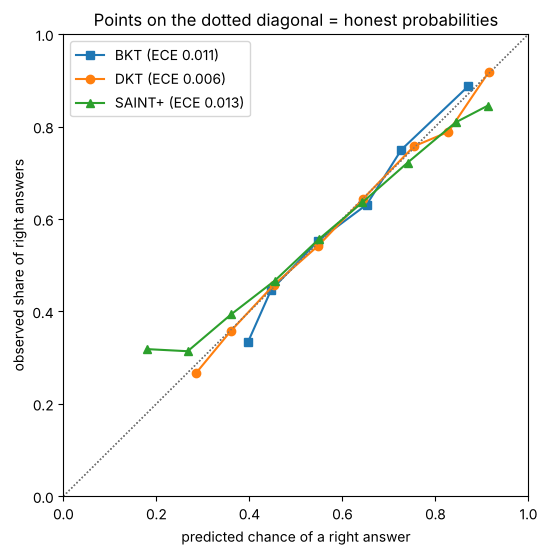

,bin,predicted,observed,answers
0,0.1-0.2,0.180,0.318,22
1,0.2-0.3,0.267,0.314,676
2,0.3-0.4,0.361,0.394,3552
3,0.4-0.5,0.455,0.467,8947
4,0.5-0.6,0.549,0.556,11569
5,0.6-0.7,0.643,0.636,7627
6,0.7-0.8,0.740,0.722,2605
7,0.8-0.9,0.843,0.809,931
8,0.9-1.0,0.912,0.845,71


In [4]:
# Concept: reliability diagram (calibration) · Production: T040, T047
fig, ax = plt.subplots(figsize=(6, 6))
for (name, (y, p)), marker in zip(preds.items(), ["s", "o", "^"]):
    X.plot_reliability(ax, y, p, f"{name} (ECE {X.expected_calibration_error(y, p):.3f})", marker=marker)
ax.set_title("Points on the dotted diagonal = honest probabilities")
plt.show()
X.calibration_table(*preds["SAINT+"]).round(3)

## The champion / challenger gate

Every week the brain is retrained (T045). The new model (the **challenger**) replaces the current
one (the **champion**) only if it is clearly better overall **and** no group of students gets
worse. Kuizi's rule (T047): at least +0.005 AUC overall, no slice (for example students with an
accommodation) losing more than 1 AUC point, and calibration not worse by more than 0.01 ECE.

<div dir="rtl" lang="ar">

## بوّابة البطل / المنافس

كل أسبوع يُعاد تدريب الدماغ (T045). النموذج الجديد (<b>المنافس</b>) لا يحلّ محلّ الحالي (<b>البطل</b>) إلا إذا كان أفضل بوضوح إجمالًا،
<b>و</b>لم تسُؤ النتائج لأي مجموعة من التلاميذ. قاعدة كويزي (T047): +0.005 على الأقل في AUC الإجمالي، ولا تخسر أي شريحة
(مثل التلاميذ ذوي التيسيرات) أكثر من نقطة AUC واحدة، ولا تسوء المعايرة بأكثر من 0.01.

</div>

In [5]:
# Concept: champion / challenger gate with fairness slices · Production: T047, T148
acc = s_test.time_multiplier.values > 1
def evaluate(y, p):
    return {"AUC": X.auc(y, p), "ECE": X.expected_calibration_error(y, p),
            "AUC accommodated": X.auc(y[acc], p[acc]), "AUC others": X.auc(y[~acc], p[~acc])}
def gate(champion, challenger):
    reasons = []
    if challenger["AUC"] < champion["AUC"] + 0.005:
        reasons.append("overall AUC gain below 0.005")
    for slice_ in ("AUC accommodated", "AUC others"):
        if challenger[slice_] < champion[slice_] - 0.01:
            reasons.append(f"{slice_} drops by more than 1 point")
    if challenger["ECE"] > champion["ECE"] + 0.01:
        reasons.append("calibration worse by more than 0.01")
    return ("PROMOTE challenger" if not reasons else "KEEP champion: " + "; ".join(reasons))
results = {name: evaluate(*preds[name]) for name in preds}
display(pd.DataFrame(results).T.round(4))
print("champion DKT vs challenger SAINT+ ->", gate(results["DKT"], results["SAINT+"]))
print("champion BKT vs challenger DKT    ->", gate(results["BKT"], results["DKT"]))

,AUC,ECE,AUC accommodated,AUC others
BKT,0.6388,0.0106,0.6270,0.6404
DKT,0.6615,0.0059,0.6489,0.6633
SAINT+,0.6222,0.0132,0.6256,0.6216


champion DKT vs challenger SAINT+ -> KEEP champion: overall AUC gain below 0.005; AUC accommodated drops by more than 1 point; AUC others drops by more than 1 point
champion BKT vs challenger DKT    -> PROMOTE challenger


### Remember
- Always test on students the model has never seen; random answers leak and flatter the model.
- AUC measures ranking; calibration (ECE) measures whether the percentages can be trusted. Kuizi needs both.
- A new model replaces the old one only through the gate: better overall, no group worse, calibration kept (T047).

<div dir="rtl" lang="ar">

### تذكّر
- اختبر دائمًا على تلاميذ لم يرهم النموذج؛ الإجابات العشوائية تسرّب المعلومات وتجمّل النموذج.
- AUC يقيس الترتيب، والمعايرة (ECE) تقيس هل يمكن الوثوق بالنسب. كويزي يحتاج إلى الاثنين.
- النموذج الجديد لا يحلّ محلّ القديم إلا عبر البوّابة: أفضل إجمالًا، ولا مجموعة تسوء، والمعايرة محفوظة (T047).

</div>